In [84]:
### Data processing
### ==============================================================================
import numpy as np
import pandas as pd

### Plots
### ==============================================================================
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use("seaborn")

### Preprocessing
### ==============================================================================
from sklearn.preprocessing import PolynomialFeatures, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

### Modeling
### ==============================================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy


### Notebook Configuration
### ==============================================================================
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', 80)

# **E**xploratory **D**ata and **A**nalysis (**EDA**) 

In [52]:
# Load dataset
data = pd.read_csv("data.csv")
data.head()

,red,green,blue,label
0,20,139,240,Blue
1,174,83,72,Brown
2,144,249,131,Green
3,168,25,156,Pink
4,30,182,136,Green


In [53]:
data.describe()

,red,green,blue
count,5007.000000,5007.000000,5007.000000
mean,127.560815,126.267825,128.333333
std,73.965384,74.910912,74.219337
min,0.000000,0.000000,0.000000
25%,63.000000,60.000000,63.000000
50%,128.000000,127.000000,130.000000
75%,191.000000,191.000000,192.000000
max,255.000000,255.000000,255.000000


In [54]:
### Check Missing values
data.isna().sum()

red      0
green    0
blue     0
label    0
dtype: int64

<AxesSubplot:>

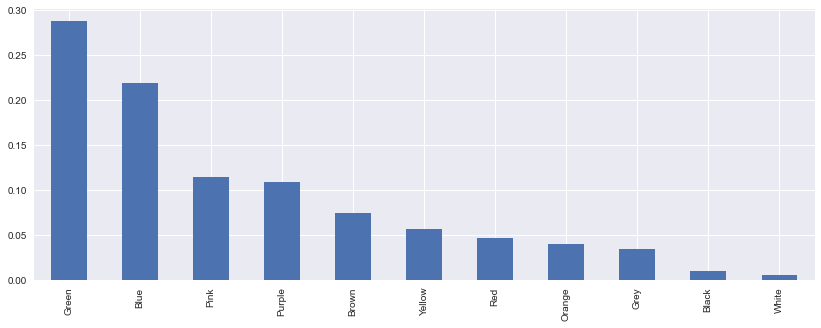

In [55]:
### Check imbalanced dataset
plt.figure(figsize=(14,5))
data.label.value_counts(normalize=True).plot.bar()

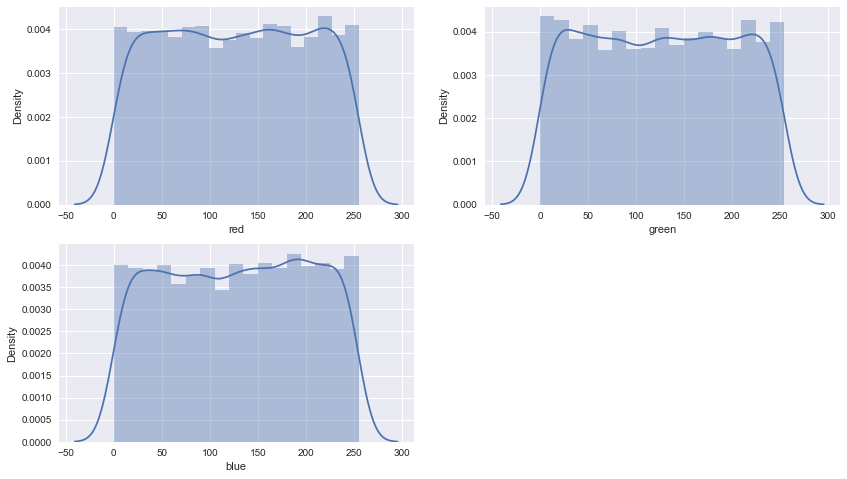

In [56]:
plt.figure(figsize=(14,8))
for i,col in enumerate(data.select_dtypes(["float","int"])):
    plt.subplot(2,2,i+1)
    sns.distplot(data[col])

<Figure size 864x576 with 0 Axes>

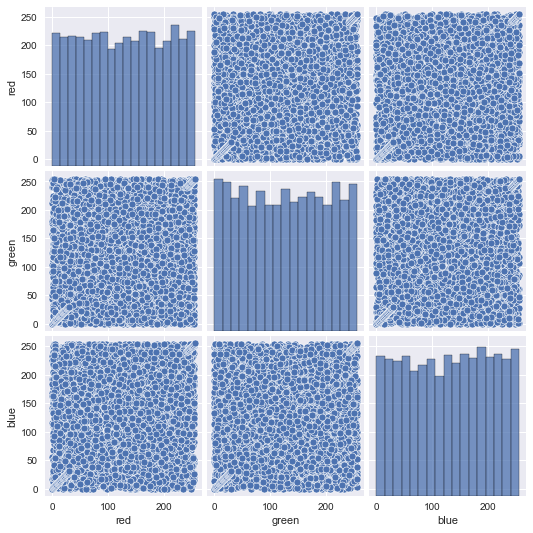

In [57]:
plt.figure(figsize=(12,8))
sns.pairplot(data.select_dtypes(["float","int"]))

<AxesSubplot:>

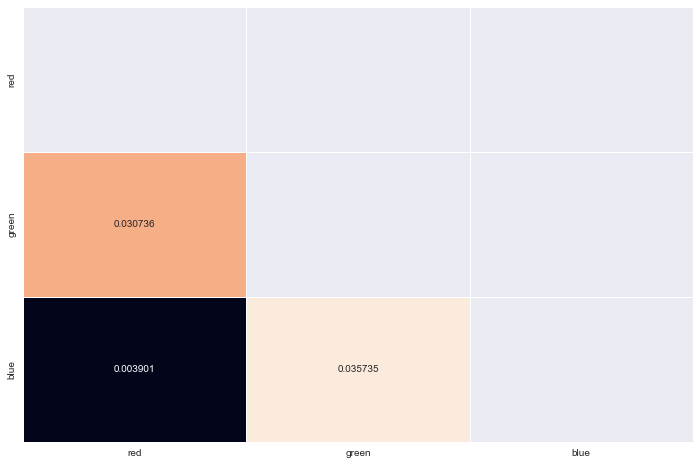

In [58]:
plt.figure(figsize=(12,8))
corr=data.select_dtypes(["float","int"]).corr()
mask=np.zeros_like(corr)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(corr, annot=True, fmt="f", mask=mask, cbar=False, linewidths=1)

# **P**re-**P**rocessing

In [79]:
df=data.copy()

In [80]:
# Label encoding
label_encoder=LabelEncoder()
df.label=label_encoder.fit_transform(data.label)

### **F**eature **E**ngineering (**FE**)

In [81]:
data_values=data.select_dtypes(["int","float"]).values

## Create Polynomial Features
poly = PolynomialFeatures(interaction_only=True)
new_vars=poly.fit_transform(data_values)

for i in range(new_vars.shape[1]):
    df[f"var_{i}"]=new_vars[:,i]

## Standardization
scaler=StandardScaler()
df.iloc[:,:]=scaler.fit_transform(df)

### **S**plitting **D**ata

In [70]:
X_train, X_test, y_train, y_test= train_test_split(df.drop("label",axis=1), df.label, random_state=25, test_size=0.2)

# **D**eep **L**earning **M**odel

In [95]:
model=Sequential([
    Dense(units=16, input_shape=(1,), activation='relu'),
    Dense(units=32, activation='relu'),
    Dense(units=2, activation='softmax'),
])


In [96]:
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_15 (Dense)            (None, 16)                32        
                                                                 
 dense_16 (Dense)            (None, 32)                544       
                                                                 
 dense_17 (Dense)            (None, 2)                 66        
                                                                 
Total params: 642
Trainable params: 642
Non-trainable params: 0
_________________________________________________________________
